<div style="background-color: #f9f9fc; color: #333366; border-radius: 12px; margin: 20px auto; padding: 20px; border: 2px solid #4c4cff; max-width: 900px; font-family: Arial, sans-serif; line-height: 1.6;">
  <h2 style="text-align: center; color: #333366;">Import Necessary Libraries</h2>

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import classification_report, confusion_matrix


<div style="background-color: #f9f9fc; color: #333366; border-radius: 12px; margin: 20px auto; padding: 20px; border: 2px solid #4c4cff; max-width: 900px; font-family: Arial, sans-serif; line-height: 1.6;">
  <h2 style="text-align: center; color: #333366;">Define Dataset Path & Classes</h2>

In [2]:
# Step 2: Define dataset path and classes
DATASET_PATH = '/kaggle/input/blood-cell-images-for-cancer-detection'
CLASSES = ['basophil', 'erythroblast', 'monocyte', 'myeloblast', 'seg_neutrophil']

# Optional: Print a quick summary of how many images per class
for class_name in CLASSES:
    folder = os.path.join(DATASET_PATH, class_name)
    num_images = len(os.listdir(folder))
    print(f"{class_name}: {num_images} images")


basophil: 1000 images
erythroblast: 1000 images
monocyte: 1000 images
myeloblast: 1000 images
seg_neutrophil: 1000 images


<div style="background-color: #f9f9fc; color: #333366; border-radius: 12px; margin: 20px auto; padding: 20px; border: 2px solid #4c4cff; max-width: 900px; font-family: Arial, sans-serif; line-height: 1.6;">
  <h2 style="text-align: center; color: #333366;"> Load & Resize the Images</h2>

In [3]:
# Step 3: Load and resize images to a fixed size
IMG_HEIGHT, IMG_WIDTH = 128, 128

images_raw = []   # will store the raw BGR images
labels = []       # will store the numeric class indices

for class_index, class_name in enumerate(CLASSES):
    folder_path = os.path.join(DATASET_PATH, class_name)
    
    for img_file in os.listdir(folder_path):
        img_path = os.path.join(folder_path, img_file)
        
        # Read the image from disk using OpenCV
        img_bgr = cv2.imread(img_path)
        
        # If image loading failed, skip
        if img_bgr is None:
            print(f"Warning: Could not load {img_path}")
            continue
        
        # Resize to (128, 128)
        img_bgr = cv2.resize(img_bgr, (IMG_HEIGHT, IMG_WIDTH))
        
        # Store
        images_raw.append(img_bgr)
        labels.append(class_index)

# Convert Python lists to NumPy arrays
images_raw = np.array(images_raw)   # shape: (N, 128, 128, 3)
labels = np.array(labels)           # shape: (N,)
print("Raw images shape:", images_raw.shape)
print("Labels shape:", labels.shape)


Raw images shape: (5000, 128, 128, 3)
Labels shape: (5000,)


<div style="background-color: #f9f9fc; color: #333366; border-radius: 12px; margin: 20px auto; padding: 20px; border: 2px solid #4c4cff; max-width: 900px; font-family: Arial, sans-serif; line-height: 1.6;">
  <h2 style="text-align: center; color: #333366;"> Optical Density (OD) Conversion</h2>

In [4]:
import numpy as np
import cv2

# Step 4.1: Define Optical Density transform function
def optical_density_transform(image_bgr):
    """
    Converts an 8-bit BGR image to Optical Density (OD) space.
    
    Args:
        image_bgr (np.array): (H, W, 3) BGR image in [0..255].
    
    Returns:
        od_image (np.array): (H, W, 3) float32 OD image.
    """
    # Convert BGR to RGB for consistency
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB).astype(np.float32)
    
    # Add +1 offset to avoid taking log(0)
    image_rgb += 1.0
    
    # Normalize by 256 for 8-bit images
    image_rgb /= 256.0
    
    # OD = -log(RGB)
    od_image = -np.log(image_rgb + 1e-8)
    
    return od_image




In [5]:
# Step 4.2: Convert all raw images to OD space
images_od = []
labels_od = labels.copy()  # Copy labels to ensure they remain unchanged

for img_bgr in images_raw:
    od_img = optical_density_transform(img_bgr)
    images_od.append(od_img)

images_od = np.array(images_od)  # shape: (N, H, W, 3)
print("OD-transformed images shape:", images_od.shape)
print("Labels shape:", labels_od.shape)  # Should match number of images

OD-transformed images shape: (5000, 128, 128, 3)
Labels shape: (5000,)


<div style="background-color: #f9f9fc; color: #333366; border-radius: 12px; margin: 20px auto; padding: 20px; border: 2px solid #4c4cff; max-width: 900px; font-family: Arial, sans-serif; line-height: 1.6;">
  <h2 style="text-align: center; color: #333366;">Anisotropic Diffusion (Fluid-Dynamics Inspired)</h2>

In [6]:
import numpy as np
import cv2

def anisotropic_diffusion(img, niter=10, kappa=20, gamma=0.2, step=(1., 1.), option=1):
    """
    Perform Perona-Malik anisotropic diffusion on a 2D grayscale image.
    
    Args:
        img   : 2D np.array (float), grayscale image
        niter : number of iterations
        kappa : conduction coefficient
        gamma : update speed (< 0.25 for stability in 2D)
        step  : (dy, dx) pixel dimensions
        option: 1 or 2 for different conduction functions
    
    Returns:
        diffused_img: 2D np.array after diffusion
    """
    img = img.astype(np.float32)  # Ensure float32 for computations
    dy, dx = step  # Step sizes
    diffused_img = img.copy()

    for _ in range(niter):
        # Compute gradients
        north = np.roll(diffused_img, -1, axis=0) - diffused_img
        south = np.roll(diffused_img, 1, axis=0) - diffused_img
        east = np.roll(diffused_img, -1, axis=1) - diffused_img
        west = np.roll(diffused_img, 1, axis=1) - diffused_img

        # Compute diffusion coefficients
        if option == 1:
            cN = np.exp(-(north / kappa) ** 2)
            cS = np.exp(-(south / kappa) ** 2)
            cE = np.exp(-(east / kappa) ** 2)
            cW = np.exp(-(west / kappa) ** 2)
        elif option == 2:
            cN = 1 / (1 + (north / kappa) ** 2)
            cS = 1 / (1 + (south / kappa) ** 2)
            cE = 1 / (1 + (east / kappa) ** 2)
            cW = 1 / (1 + (west / kappa) ** 2)

        # Update image
        diffused_img += gamma * (
            (cN * north) + (cS * south) + (cE * east) + (cW * west)
        )

    return diffused_img


def anisotropic_diffusion_color(img, niter=10, kappa=20, gamma=0.2, step=(1., 1.), option=1):
    """
    Perform Perona-Malik anisotropic diffusion on a 3D color image (RGB).
    
    Args:
        img   : 3D np.array (float), color image (H, W, 3)
        niter : number of iterations
        kappa : conduction coefficient
        gamma : update speed (< 0.25 for stability in 2D)
        step  : (dy, dx) pixel dimensions
        option: 1 or 2 for different conduction functions
    
    Returns:
        diffused_img: 3D np.array after diffusion
    """
    channels = cv2.split(img)
    diffused_channels = [anisotropic_diffusion(ch, niter, kappa, gamma, step, option) for ch in channels]
    return cv2.merge(diffused_channels)

In [7]:
# Ensure the labels remain unchanged
images_diffused = []
labels_updated = labels.copy()  # Assuming labels is a NumPy array or list

for od_img in images_od:
    diffused_img = anisotropic_diffusion_color(od_img, niter=10, kappa=20, gamma=0.2)
    images_diffused.append(diffused_img)

images_diffused = np.array(images_diffused)
print("Diffused images shape:", images_diffused.shape)
print("Labels shape:", labels_updated.shape)  # Should match number of images


Diffused images shape: (5000, 128, 128, 3)
Labels shape: (5000,)


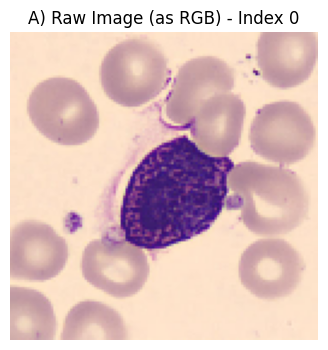

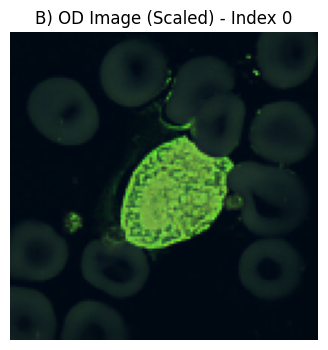

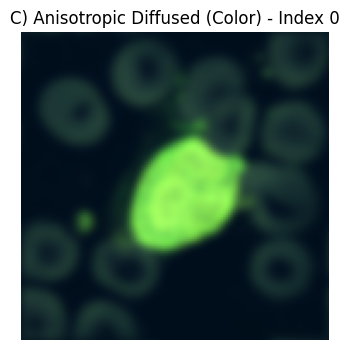

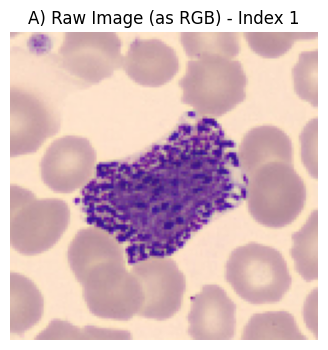

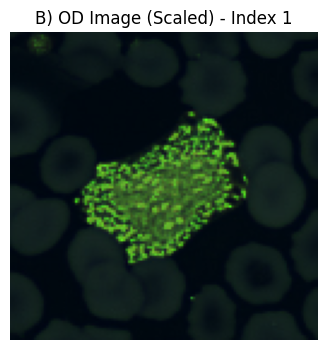

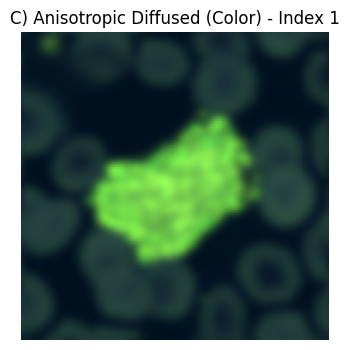

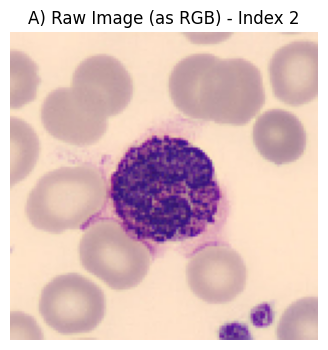

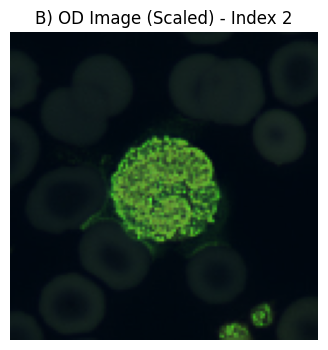

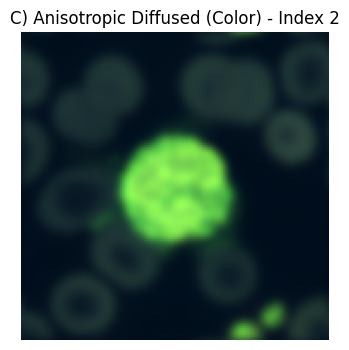

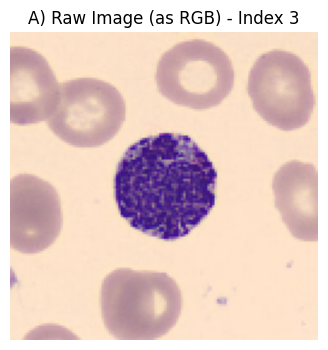

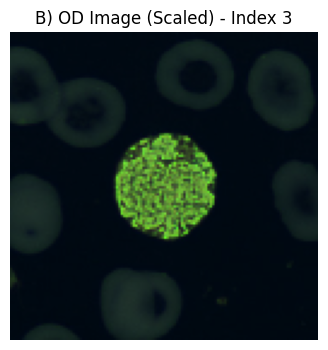

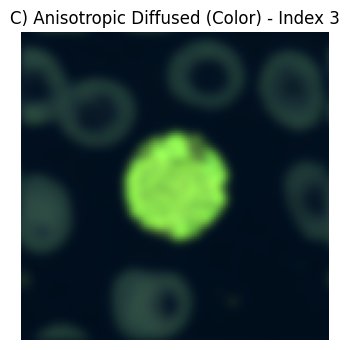

In [8]:
# Import required libraries
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Define the function to display images
def show_image(img, title='', cmap=None):
    """Simple utility to display an image with matplotlib."""
    plt.figure(figsize=(4, 4))
    if cmap:
        plt.imshow(img, cmap=cmap)
    else:
        # If it's 3-channel, let matplotlib interpret it as RGB
        plt.imshow(img)
    plt.title(title)
    plt.axis('off')
    plt.show()

# Pick multiple example indices (e.g., first 4 images)
example_indices = [0, 1, 2, 3]

for example_idx in example_indices:
    # A) Raw (BGR) -> Convert to RGB for display
    raw_rgb = cv2.cvtColor(images_raw[example_idx], cv2.COLOR_BGR2RGB)
    show_image(raw_rgb, title=f"A) Raw Image (as RGB) - Index {example_idx}")

    # B) OD (3 channels) - Min-max scale it for visualization
    od_min, od_max = images_od[example_idx].min(), images_od[example_idx].max()
    od_display = (images_od[example_idx] - od_min) / (od_max - od_min + 1e-8)
    show_image(od_display, title=f"B) OD Image (Scaled) - Index {example_idx}")

    # C) Diffused Image (Now in Color) - Min-max scale for visualization
    diff_min, diff_max = images_diffused[example_idx].min(), images_diffused[example_idx].max()
    diff_display = (images_diffused[example_idx] - diff_min) / (diff_max - diff_min + 1e-8)
    show_image(diff_display, title=f"C) Anisotropic Diffused (Color) - Index {example_idx}")  # No cmap='gray'


<div style="background-color: #f9f9fc; color: #333366; border-radius: 12px; margin: 20px auto; padding: 20px; border: 2px solid #4c4cff; max-width: 900px; font-family: Arial, sans-serif; line-height: 1.6;">
  <h2 style="text-align: center; color: #333366;"> Biologically Plausible Color/Stain Augmentation</h2>

In [9]:
import cv2
import numpy as np

def color_stain_augmentation(
    od_image, 
    max_hue_shift=0.05,        # increased from 0.02
    max_saturation_shift=0.4,  # increased from 0.2
    brightness_range=(0.8, 1.2),  # widened from (0.9, 1.1)
    output_in_od=True
):
    """
    Apply a stronger, biologically plausible color jitter to an OD (or RGB) image.
    
    Args:
        od_image: (H, W, 3) float32 array in OD or standard RGB space.
                  Values can range beyond [0..1] if in OD; we clamp as needed.
        max_hue_shift: float, max fraction of hue shift (0.05 => up to ~5% hue shift).
        max_saturation_shift: float, max proportion to scale saturation (0.4 => ±40%).
        brightness_range: (min_brightness, max_brightness) for overall brightness scaling.
        output_in_od: bool, if True returns OD space; if False returns RGB space.
        
    Returns:
        aug_image: (H, W, 3) array with color augmentation applied, 
                   either in OD or RGB (float32).
    """
    # 1) Convert from OD to pseudo-RGB if needed
    #    We'll invert the OD as exp(-OD) and clamp to [0..1].
    pseudo_rgb = np.exp(-np.clip(od_image, 0, 5))  # clamp OD for stability
    
    # 2) Convert to 8-bit RGB for OpenCV’s HSV operations
    pseudo_rgb_8u = (np.clip(pseudo_rgb, 0, 1) * 255).astype(np.uint8)
    hsv_img = cv2.cvtColor(pseudo_rgb_8u, cv2.COLOR_RGB2HSV).astype(np.float32)
    
    # 3) Random hue shift in [0..180]
    hue_shift = np.random.uniform(-max_hue_shift, max_hue_shift)
    hue_shift_val = hue_shift * 180  # convert fraction to degrees
    hsv_img[..., 0] = (hsv_img[..., 0] + hue_shift_val) % 180
    
    # 4) Random saturation scaling
    sat_scale = 1.0 + np.random.uniform(-max_saturation_shift, max_saturation_shift)
    hsv_img[..., 1] = np.clip(hsv_img[..., 1] * sat_scale, 0, 255)
    
    # 5) Random brightness scaling
    brightness_factor = np.random.uniform(brightness_range[0], brightness_range[1])
    hsv_img[..., 2] = np.clip(hsv_img[..., 2] * brightness_factor, 0, 255)
    
    # 6) Convert back to RGB
    aug_rgb_8u = cv2.cvtColor(hsv_img.astype(np.uint8), cv2.COLOR_HSV2RGB)
    
    # 7) Convert to float [0..1]
    aug_rgb = aug_rgb_8u.astype(np.float32) / 255.0
    
    # 8) Optionally return OD or stay in RGB
    if output_in_od:
        # Convert back to OD space
        aug_od = -np.log(np.clip(aug_rgb, 1e-8, 1.0)) 
        return aug_od.astype(np.float32)
    else:
        # Return the augmented image in RGB
        return aug_rgb.astype(np.float32)


<div style="background-color: #f9f9fc; color: #333366; border-radius: 12px; margin: 20px auto; padding: 20px; border: 2px solid #4c4cff; max-width: 900px; font-family: Arial, sans-serif; line-height: 1.6;">
  <h2 style="text-align: center; color: #333366;">Shape-Constrained Morphological Augmentation</h2>

In [10]:
import numpy as np
import cv2

def shape_constrained_rbc_augmentation(
    od_img, 
    morph_prob=1.0,            # default to always apply for a stronger effect
    threshold_value=100,       # can be adjusted or replaced with Otsu
    kernel_min=3, kernel_max=8,# larger kernel range
    morph_iterations=2,        # apply morphological operation multiple times
    od_shift=0.4               # how much to reduce OD within RBC region
):
    """
    Apply random morphological operations to RBC regions in a simplified manner,
    simulating shape deformations (e.g., RBCs more spherical or elongated).
    
    Args:
        od_img:             (H, W, 3) OD image or (H, W) single-channel OD
        morph_prob:         Probability of applying morphological operation
        threshold_value:    Binary threshold for RBC region extraction
        kernel_min:         Minimum size for elliptical structuring element
        kernel_max:         Maximum size for elliptical structuring element
        morph_iterations:   How many times to apply erode/dilate
        od_shift:           Fraction by which we reduce OD in RBC region (e.g. 0.4 => 40%)
        
    Returns:
        morphed_od: same shape as od_img with morphological changes
    """
    # 1) Randomly skip augmentation if probability not met
    if np.random.rand() > morph_prob:
        return od_img
    
    # 2) Extract or create a single channel for thresholding if 3-channel
    if od_img.ndim == 3:
        od_gray = np.mean(od_img, axis=-1)
    else:
        od_gray = od_img
    
    # 3) Invert OD to pseudo-grayscale
    pseudo_gray = np.exp(-np.clip(od_gray, 0, 5))  # ~ [0..1]
    
    # 4) Create a binary mask (simplistic RBC region detection)
    mask_8u = (pseudo_gray * 255).astype(np.uint8)
    _, bin_mask = cv2.threshold(mask_8u, threshold_value, 255, cv2.THRESH_BINARY)
    
    # 5) Choose erode or dilate randomly
    operation_type = np.random.choice(["erode", "dilate"])
    kernel_size = np.random.randint(kernel_min, kernel_max)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel_size, kernel_size))
    
    # 6) Apply morphological op multiple times for stronger effect
    morphed_mask = bin_mask.copy()
    for _ in range(morph_iterations):
        if operation_type == "erode":
            morphed_mask = cv2.erode(morphed_mask, kernel, iterations=1)
        else:
            morphed_mask = cv2.dilate(morphed_mask, kernel, iterations=1)
    
    # 7) Convert morphed_mask back to float [0..1]
    morphed_mask_f = morphed_mask.astype(np.float32) / 255.0
    
    # 8) Reduce OD in RBC region by od_shift fraction
    #    Higher od_shift => RBC region appears "thinner" in OD domain
    if od_img.ndim == 3:
        # multi-channel: apply mask to each channel
        morphed_od = od_img * (1 - od_shift * morphed_mask_f[..., None])
    else:
        morphed_od = od_img * (1 - od_shift * morphed_mask_f)
    
    return morphed_od


In [11]:
aug_images = []
aug_labels = []

def augmentation_function(img_od):
    # Perform whichever augmentations you want
    img_aug = color_stain_augmentation(img_od)
    img_aug = shape_constrained_rbc_augmentation(img_aug)
    return img_aug


for img_od, label in zip(images_od, labels):
    # Always keep the original
    aug_images.append(img_od)
    aug_labels.append(label)
    
    # Create one (or more) augmented version(s)
    aug_img = augmentation_function(img_od)
    
    # Append the augmented version
    aug_images.append(aug_img)
    aug_labels.append(label)

aug_images = np.array(aug_images)
aug_labels = np.array(aug_labels)

print("Augmented dataset shape:", aug_images.shape)
print("Augmented labels shape:", aug_labels.shape)


Augmented dataset shape: (10000, 128, 128, 3)
Augmented labels shape: (10000,)


In [12]:
import numpy as np

def od_to_displayable_rgb(od_image):
    """
    Converts a float32 OD image (H, W, 3) to a pseudo-RGB in [0..1].
    """
    # 1) Invert using exp(-OD). 
    #    Clip the OD for stability (e.g., between 0 and 5) so exp() doesn't blow up
    pseudo_rgb = np.exp(-np.clip(od_image, 0, 5))  

    # 2) Clip to [0..1] just to be safe
    pseudo_rgb = np.clip(pseudo_rgb, 0, 1)
    return pseudo_rgb


In [13]:
import matplotlib.pyplot as plt

def show_real_vs_aug(original_od, augmented_od, title_real="Original", title_aug="Augmented"):
    """
    Displays two images side by side. Both inputs are OD images.
    We convert OD to pseudo-RGB for visualization.
    """
    # Convert OD to displayable RGB
    orig_rgb = od_to_displayable_rgb(original_od)
    aug_rgb = od_to_displayable_rgb(augmented_od)
    
    # Plot side by side
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    
    axes[0].imshow(orig_rgb)
    axes[0].set_title(title_real)
    axes[0].axis('off')
    
    axes[1].imshow(aug_rgb)
    axes[1].set_title(title_aug)
    axes[1].axis('off')
    
    plt.tight_layout()
    plt.show()


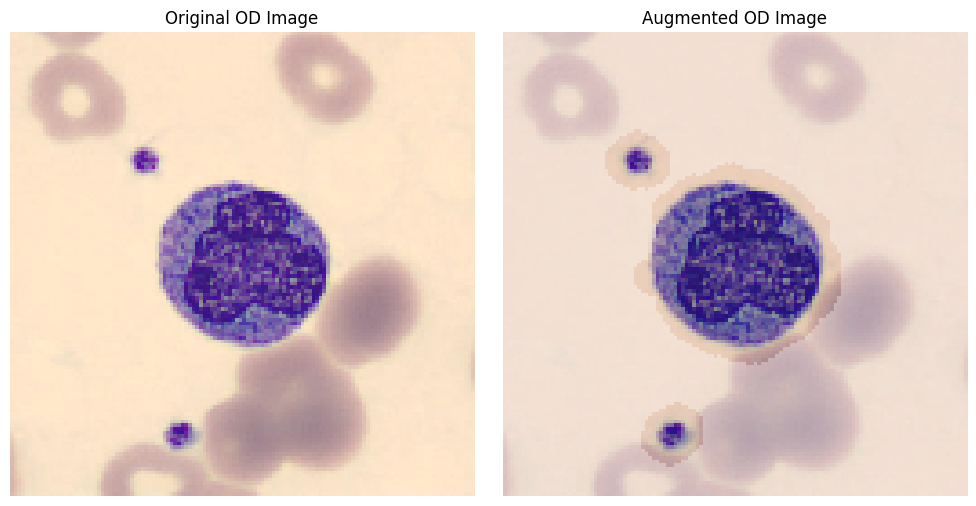

In [14]:
import random

# Let's pick a random sample
idx = random.randint(0, len(images_od) - 1)

# 1) Original OD image
original_od = images_od[idx]

# 2) Augmented OD image
augmented_od = augmentation_function(original_od)

# 3) Display side by side
show_real_vs_aug(original_od, augmented_od,
                 title_real="Original OD Image",
                 title_aug="Augmented OD Image")


<div style="background-color: #f9f9fc; color: #333366; border-radius: 12px; margin: 20px auto; padding: 20px; border: 2px solid #4c4cff; max-width: 900px; font-family: Arial, sans-serif; line-height: 1.6;">
  <h2 style="text-align: center; color: #333366;">Convert Labels to Categorical & Split the Dataset</h2>

In [15]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical

# Convert Labels to Categorical Format
labels_categorical = to_categorical(labels, num_classes=5)

# Split Dataset
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    images_raw, labels_categorical,
    test_size=0.2, random_state=42, stratify=labels_categorical
)

X_train_od, X_test_od = train_test_split(
    images_od, test_size=0.2, random_state=42, stratify=labels_categorical
)

X_train_diffused, X_test_diffused = train_test_split(
    images_diffused, test_size=0.2, random_state=42, stratify=labels_categorical
)

# Print Dataset Shapes
print("Train Raw Images:", X_train_raw.shape)
print("Train OD Images:", X_train_od.shape)
print("Train Diffused Images:", X_train_diffused.shape)


Train Raw Images: (4000, 128, 128, 3)
Train OD Images: (4000, 128, 128, 3)
Train Diffused Images: (4000, 128, 128, 3)


<div style="background-color: #f9f9fc; color: #333366; border-radius: 12px; margin: 20px auto; padding: 20px; border: 2px solid #4c4cff; max-width: 900px; font-family: Arial, sans-serif; line-height: 1.6;">
  <h2 style="text-align: center; color: #333366;">Model Training & Evaluation</h2>

In [16]:
import tensorflow as tf
from tensorflow.keras import layers, Model, Input

def model(
    raw_shape=(128,128,3),
    od_shape=(128,128,3),
    diffused_shape=(128,128,3),  # ✅ Updated from (128,128,1) to (128,128,3)
    num_classes=5
):
    """
    Multi-Stream CNN with Cross-Attention Fusion.
    """

    # ----- Stream 1: Raw Image -----
    raw_input = Input(shape=raw_shape, name='raw_input')
    x = layers.Conv2D(32, (3,3), activation='relu', padding='same')(raw_input)
    x = layers.MaxPooling2D((2,2))(x)

    # Residual Block
    res = x
    x = layers.Conv2D(64, (3,3), activation='relu', padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(64, (3,3), activation=None, padding='same')(x)
    x = layers.BatchNormalization()(x)
    res = layers.Conv2D(64, (1,1), padding='same')(res)  # 1x1 Conv Fix
    x = layers.Add()([x, res])
    x = layers.ReLU()(x)
    
    x = layers.MaxPooling2D((2,2))(x)
    x = layers.Conv2D(128, (3,3), activation='relu', padding='same')(x)
    x = layers.GlobalAveragePooling2D()(x)
    raw_features = layers.Dense(128, activation='relu')(x)

    # ----- Stream 2: OD Image -----
    od_input = Input(shape=od_shape, name='od_input')
    y = layers.Conv2D(32, (3,3), activation='relu', padding='same')(od_input)
    y = layers.MaxPooling2D((2,2))(y)

    # Multi-Scale Feature Extraction
    y1 = layers.Conv2D(32, (1,1), activation='relu', padding='same')(y)
    y2 = layers.Conv2D(32, (3,3), activation='relu', padding='same')(y)
    y3 = layers.Conv2D(32, (5,5), activation='relu', padding='same')(y)
    y = layers.Concatenate()([y1, y2, y3])
    
    y = layers.MaxPooling2D((2,2))(y)
    y = layers.Conv2D(64, (3,3), activation='relu', padding='same')(y)
    y = layers.GlobalAveragePooling2D()(y)
    od_features = layers.Dense(128, activation='relu')(y)

    # ----- Stream 3: Diffused Image (Now RGB) -----
    diffused_input = Input(shape=diffused_shape, name='diffused_input')  # ✅ Updated to RGB
    z = layers.Conv2D(32, (3,3), activation='relu', padding='same')(diffused_input)
    z = layers.MaxPooling2D((2,2))(z)

    # Depthwise Separable Convolutions for Efficiency
    z = layers.SeparableConv2D(64, (3,3), activation='relu', padding='same')(z)
    z = layers.MaxPooling2D((2,2))(z)
    z = layers.SeparableConv2D(128, (3,3), activation='relu', padding='same')(z)

    z = layers.GlobalAveragePooling2D()(z)
    diffused_features = layers.Dense(128, activation='relu')(z)

    # ----- Cross-Attention Fusion -----
    fused = layers.Concatenate()([raw_features, od_features, diffused_features])  # Shape = (Batch, 384)

    # 🔥 Fix: Ensure attention vector has the same shape as `fused` (384,)
    attention = layers.Dense(384, activation='sigmoid')(fused)
    fused = layers.Multiply()([fused, attention])

    fused = layers.Dense(64, activation='relu')(fused)
    fused = layers.Dropout(0.3)(fused)
    output = layers.Dense(num_classes, activation='softmax')(fused)

    # ----- Build Model -----
    model = Model(inputs=[raw_input, od_input, diffused_input], outputs=output)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

# Instantiate the Model
model = model()
model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ raw_input (InputLayer)    │ (None, 128, 128, 3)    │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d (Conv2D)           │ (None, 128, 128, 32)   │            896 │ raw_input[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d             │ (None, 64, 64, 32)     │              0 │ conv2d[0][0]           │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_1 (Conv2D)         │ (None, 64, 64, 64)     │         18,496 │ max_pooling2d[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization       │ (None, 64, 64, 64)     │            256 │ conv2d_1[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ od_input (InputLayer)     │ (None, 128, 128, 3)    │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_2 (Conv2D)         │ (None, 64, 64, 64)     │         36,928 │ batch_normalization[0… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_5 (Conv2D)         │ (None, 128, 128, 32)   │            896 │ od_input[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ diffused_input            │ (None, 128, 128, 3)    │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_1     │ (None, 64, 64, 64)     │            256 │ conv2d_2[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_3 (Conv2D)         │ (None, 64, 64, 64)     │          2,112 │ max_pooling2d[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d_2           │ (None, 64, 64, 32)     │              0 │ conv2d_5[0][0]         │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_10 (Conv2D)        │ (None, 128, 128, 32)   │            896 │ diffused_input[0][0]   │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ add (Add)                 │ (None, 64, 64, 64)     │              0 │ batch_normalization_1… │
│                           │                        │                │ conv2d_3[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_6 (Conv2D)         │ (None, 64, 64, 32)     │          1,056 │ max_pooling2d_2[0][0]  │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_7 (Conv2D)         │ (None, 64, 64, 32)     │          9,248 │ max_pooling2d_2[0][0]  │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_8 (Conv2D)    

 Total params: 451,333 (1.72 MB)

 Trainable params: 451,077 (1.72 MB)

 Non-trainable params: 256 (1.00 KB)

In [17]:
# Train for the initial number of epochs
history = model.fit(
    [X_train_raw, X_train_od, X_train_diffused],  # Three Inputs
    y_train,
    validation_data=([X_test_raw, X_test_od, X_test_diffused], y_test),
    epochs=50,
    batch_size=32
)

print("Final training complete! ✅")


Epoch 1/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 27s 92ms/step - accuracy: 0.2825 - loss: 2.9813 - val_accuracy: 0.5440 - val_loss: 0.9351
Epoch 2/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 56ms/step - accuracy: 0.5993 - loss: 0.9175 - val_accuracy: 0.7180 - val_loss: 0.6253
Epoch 3/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 56ms/step - accuracy: 0.7357 - loss: 0.6339 - val_accuracy: 0.8870 - val_loss: 0.4069
Epoch 4/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 56ms/step - accuracy: 0.8073 - loss: 0.5044 - val_accuracy: 0.7950 - val_loss: 0.3977
Epoch 5/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 56ms/step - accuracy: 0.8642 - loss: 0.3873 - val_accuracy: 0.9190 - val_loss: 0.2610
Epoch 6/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 56ms/step - accuracy: 0.8751 - loss: 0.3631 - val_accuracy: 0.8830 - val_loss: 0.2839
Epoch 7/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 57ms/step - accuracy: 0.8866 - loss: 0.3179 - val_accuracy: 0.9430 - val_loss: 0.1753
Epoch 8/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 57ms/step - accuracy: 0.9210 - loss: 0.2629 - val_acc

In [18]:
test_loss, test_acc = model.evaluate(
    [X_test_raw, X_test_od, X_test_diffused],
    y_test,
    batch_size=32
)
print(f"Test Loss: {test_loss:.4f}, Test Accuracy: {test_acc:.4f}")


32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9834 - loss: 0.0523
Test Loss: 0.0660, Test Accuracy: 0.9790


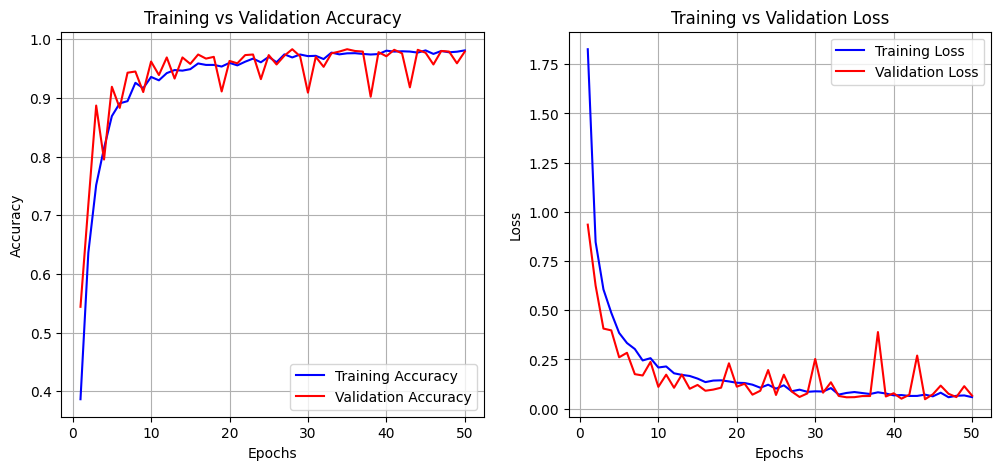

In [19]:
import matplotlib.pyplot as plt

def plot_full_training_history(history):
    """
    Plots the training and validation accuracy and loss from the training history.

    Args:
        history: Keras History object after model training.
    """
    # Extract training history
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)

    # Plot Accuracy
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'b-', label='Training Accuracy')
    plt.plot(epochs, val_acc, 'r-', label='Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.title('Training vs Validation Accuracy')
    plt.legend()
    plt.grid(True)

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'b-', label='Training Loss')
    plt.plot(epochs, val_loss, 'r-', label='Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Training vs Validation Loss')
    plt.legend()
    plt.grid(True)

    # Show plots
    plt.show()

# Call this function after training
# Example:
plot_full_training_history(history)

In [20]:
import tensorflow as tf
import numpy as np
from tensorflow.keras import backend as K

def compute_flops_and_gmacs(model):
    """
    Computes FLOPs, GMACs, MACs, and GFLOPs for a multi-input Keras model.

    Args:
        model: Keras Model instance.

    Returns:
        None (Prints FLOPs, GMACs, MACs, and GFLOPs)
    """
    try:
        # Create dummy inputs matching the model's input shape (for all 3 inputs)
        raw_shape = (1,) + tuple(model.input[0].shape[1:])  # First input shape
        od_shape = (1,) + tuple(model.input[1].shape[1:])   # Second input shape
        diffused_shape = (1,) + tuple(model.input[2].shape[1:])  # Third input shape

        # Generate random tensors for each input
        raw_input = tf.ones(raw_shape, dtype=tf.float32)
        od_input = tf.ones(od_shape, dtype=tf.float32)
        diffused_input = tf.ones(diffused_shape, dtype=tf.float32)

        # Convert the model to a concrete function with multiple inputs
        concrete_func = tf.function(lambda raw, od, diffused: model([raw, od, diffused]))
        concrete_func = concrete_func.get_concrete_function(raw_input, od_input, diffused_input)

        # Freeze the function to a static computational graph
        from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2
        frozen_func = convert_variables_to_constants_v2(concrete_func)

        # Compute FLOPs using TensorFlow profiler
        run_meta = tf.compat.v1.RunMetadata()
        opts = tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()

        flops = tf.compat.v1.profiler.profile(
            graph=frozen_func.graph,
            run_meta=run_meta,
            options=opts
        )

        # Convert FLOPs to GMACs, MACs, and GFLOPs
        total_flops = flops.total_float_ops
        macs = total_flops / 2  # Since 1 MAC = 2 FLOPs
        gmacs = macs / 1e9  # Convert to Giga MACs
        gflops = total_flops / 1e9  # Convert to Giga FLOPs

        # Print Results
        print(f"Total FLOPs  : {total_flops:,}")
        print(f"Total MACs   : {macs:,}")
        print(f"Total GMACs  : {gmacs:.3f} GMACs")
        print(f"Total GFLOPs : {gflops:.3f} GFLOPs")

    except Exception as e:
        print(f"Error computing FLOPs: {e}")

# Example usage:
compute_flops_and_gmacs(model)


Total FLOPs  : 1,157,532,254
Total MACs   : 578,766,127.0
Total GMACs  : 0.579 GMACs
Total GFLOPs : 1.158 GFLOPs


32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step


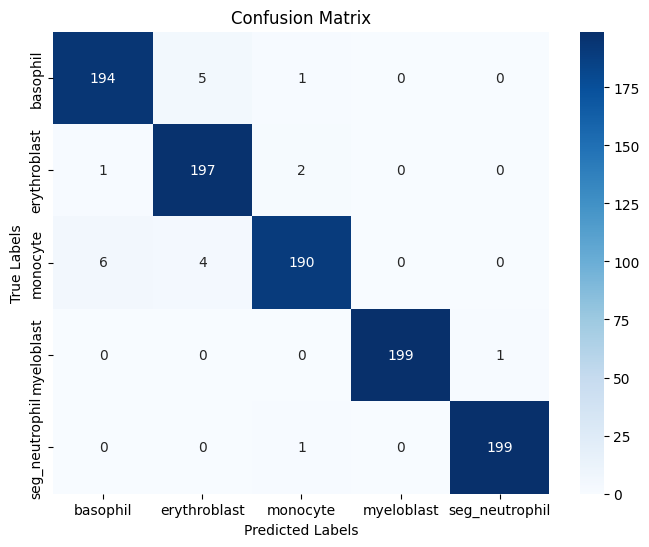

In [21]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

def plot_confusion_matrix(y_true, y_pred, class_names):
    """
    Plots a confusion matrix using seaborn heatmap.

    Args:
        y_true: Ground truth labels
        y_pred: Predicted labels
        class_names: List of class names
    """
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.title('Confusion Matrix')
    plt.show()

# Example usage:
# Convert y_test from one-hot encoding to integer labels
y_test_int = np.argmax(y_test, axis=1)

# Compute predictions
y_pred_classes = np.argmax(model.predict([X_test_raw, X_test_od, X_test_diffused]), axis=1)

# Now call the function with integer labels
plot_confusion_matrix(y_test_int, y_pred_classes, class_names=['basophil', 'erythroblast', 'monocyte', 'myeloblast', 'seg_neutrophil'])



32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


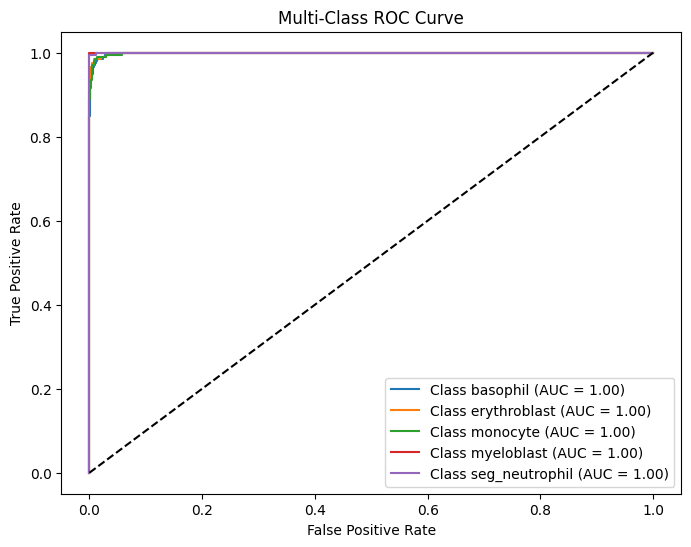

In [23]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

def plot_multiclass_roc(y_true, y_probs, class_names):
    """
    Plots the Multi-Class ROC Curve.

    Args:
        y_true: Ground truth labels (integer encoded)
        y_probs: Model probability predictions
        class_names: List of class names
    """
    y_true_bin = label_binarize(y_true, classes=range(len(class_names)))
    plt.figure(figsize=(8, 6))

    for i in range(len(class_names)):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_probs[:, i])
        plt.plot(fpr, tpr, label=f'Class {class_names[i]} (AUC = {auc(fpr, tpr):.2f})')

    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Multi-Class ROC Curve')
    plt.legend()
    plt.show()

# Example usage:
y_probs = model.predict([X_test_raw, X_test_od, X_test_diffused])
# Define class names
class_names = ['basophil', 'erythroblast', 'monocyte', 'myeloblast', 'seg_neutrophil']

# Now call the function correctly
plot_multiclass_roc(y_test, y_probs, class_names=class_names)



  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━

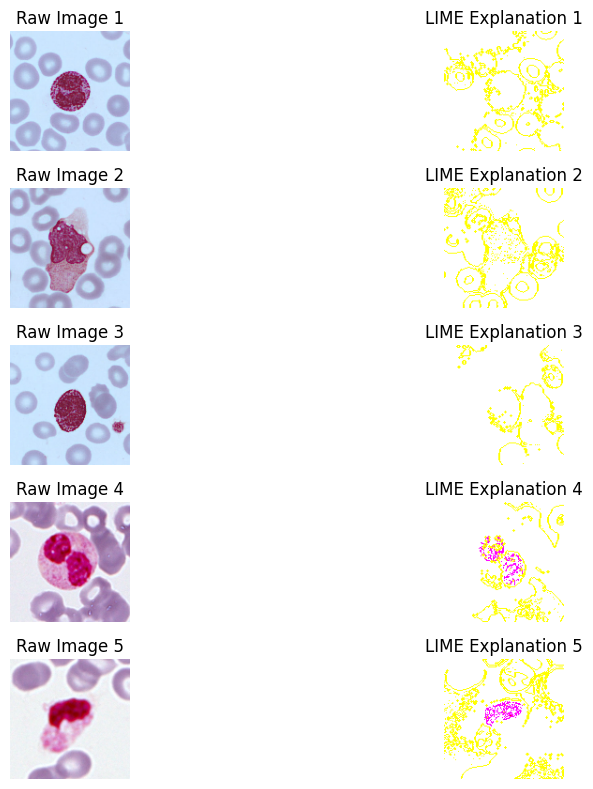

In [25]:
import matplotlib.pyplot as plt
import lime
import lime.lime_image
from skimage.segmentation import mark_boundaries
import numpy as np

def explain_with_lime(model, X_test_raw, num_samples=5, num_features=10):
    """
    Uses LIME to explain the model's decision for multiple test images.

    Args:
        model: Trained Keras model.
        X_test_raw: Raw test images.
        num_samples: Number of images to visualize.
        num_features: Number of superpixels to highlight.
    """
    explainer = lime.lime_image.LimeImageExplainer()

    plt.figure(figsize=(12, 8))
    
    # Select random samples to explain
    indices = np.random.choice(len(X_test_raw), num_samples, replace=False)

    for i, idx in enumerate(indices):
        X_sample = X_test_raw[idx]
        
        def predict_fn(images):
            return model.predict([images, images, images])  # Pass through all three inputs

        explanation = explainer.explain_instance(
            X_sample.astype('double'),
            predict_fn,
            top_labels=5,
            hide_color=0,
            num_samples=1000
        )

        temp, mask = explanation.get_image_and_mask(
            explanation.top_labels[0],
            positive_only=True,
            num_features=num_features,
            hide_rest=False
        )

        # Plot Raw Image and LIME Explanation
        plt.subplot(num_samples, 2, i * 2 + 1)
        plt.imshow(X_sample)
        plt.title(f"Raw Image {i+1}")
        plt.axis('off')

        plt.subplot(num_samples, 2, i * 2 + 2)
        plt.imshow(mark_boundaries(temp, mask))
        plt.title(f"LIME Explanation {i+1}")
        plt.axis('off')

    plt.tight_layout()
    plt.show()

# Example usage:
explain_with_lime(model, X_test_raw, num_samples=5, num_features=10)


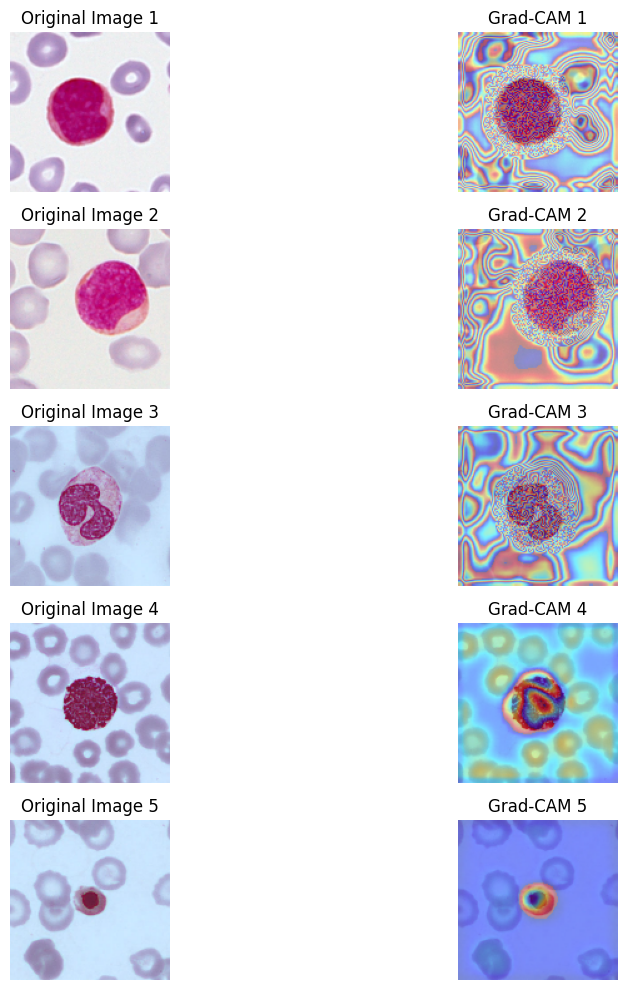

In [39]:
def grad_cam_multiple_images(model, X_test_raw, X_test_od, X_test_diffused, class_idx, num_samples=5):
    """
    Generates Grad-CAM heatmaps for multiple images in a multi-input model.

    Args:
        model: Trained Keras model.
        X_test_raw: Raw test images.
        X_test_od: Optical Density transformed test images.
        X_test_diffused: Diffused test images.
        class_idx: Target class index for visualization.
        num_samples: Number of images to visualize.
    """
    plt.figure(figsize=(12, num_samples * 2))

    # Select random samples to visualize
    indices = np.random.choice(len(X_test_raw), num_samples, replace=False)

    for i, idx in enumerate(indices):
        raw_image = np.expand_dims(X_test_raw[idx], axis=0)
        od_image = np.expand_dims(X_test_od[idx], axis=0)
        diffused_image = np.expand_dims(X_test_diffused[idx], axis=0)

        # Identify the last convolutional layer
        last_conv_layer = None
        for layer in model.layers:
            if isinstance(layer, tf.keras.layers.Conv2D):
                last_conv_layer = layer.name

        if last_conv_layer is None:
            raise ValueError("No Conv2D layers found in the model.")

        # Create a model that maps input to the last conv layer and predictions
        grad_model = tf.keras.models.Model(
            inputs=model.inputs,
            outputs=[model.get_layer(last_conv_layer).output, model.output]
        )

        with tf.GradientTape() as tape:
            conv_outputs, predictions = grad_model([raw_image, od_image, diffused_image])
            loss = predictions[:, class_idx]

        # Compute gradients
        grads = tape.gradient(loss, conv_outputs)
        pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

        # Generate heatmap
        conv_outputs = conv_outputs[0]
        heatmap = np.dot(conv_outputs, pooled_grads.numpy().reshape(-1, 1)).squeeze()

        # Normalize heatmap
        if np.max(heatmap) != 0:
            heatmap /= np.max(heatmap)

        # Resize heatmap
        heatmap = cv2.resize(heatmap, (raw_image.shape[2], raw_image.shape[1]))
        heatmap = np.uint8(255 * heatmap)
        heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

        # Superimpose the heatmap on the raw image
        superimposed_img = cv2.addWeighted(raw_image[0].astype("uint8"), 0.6, heatmap, 0.4, 0)

        # Display original and Grad-CAM image
        plt.subplot(num_samples, 2, 2 * i + 1)
        plt.imshow(raw_image[0].astype("uint8"))
        plt.title(f"Original Image {i+1}")
        plt.axis("off")

        plt.subplot(num_samples, 2, 2 * i + 2)
        plt.imshow(superimposed_img.astype("uint8"))
        plt.title(f"Grad-CAM {i+1}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

# Example usage:
grad_cam_multiple_images(model, X_test_raw, X_test_od, X_test_diffused, class_idx=0, num_samples=5)


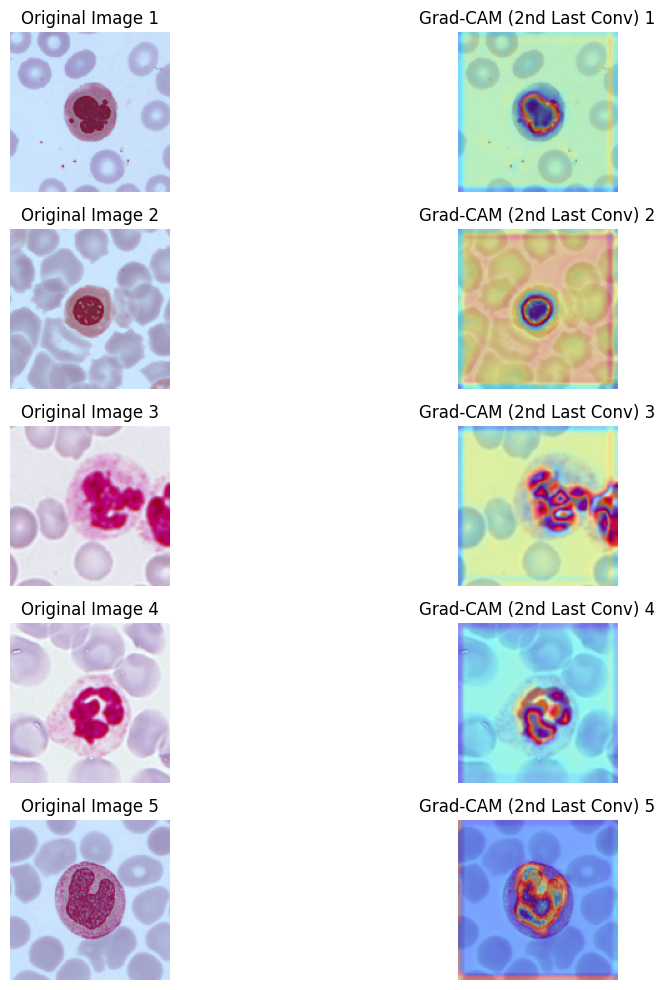

In [33]:
def grad_cam_multiple_images(model, X_test_raw, X_test_od, X_test_diffused, class_idx, num_samples=5):
    """
    Generates Grad-CAM heatmaps for multiple images in a multi-input model using the second last Conv2D layer.

    Args:
        model: Trained Keras model.
        X_test_raw: Raw test images.
        X_test_od: Optical Density transformed test images.
        X_test_diffused: Diffused test images.
        class_idx: Target class index for visualization.
        num_samples: Number of images to visualize.
    """
    plt.figure(figsize=(12, num_samples * 2))

    # Select random samples to visualize
    indices = np.random.choice(len(X_test_raw), num_samples, replace=False)

    # Identify the second last Conv2D layer
    conv_layers = [layer.name for layer in model.layers if isinstance(layer, tf.keras.layers.Conv2D)]
    if len(conv_layers) < 2:
        raise ValueError("Not enough Conv2D layers in the model for Grad-CAM.")

    second_last_conv_layer = conv_layers[-2]  # Select the second last Conv2D layer

    for i, idx in enumerate(indices):
        raw_image = np.expand_dims(X_test_raw[idx], axis=0)
        od_image = np.expand_dims(X_test_od[idx], axis=0)
        diffused_image = np.expand_dims(X_test_diffused[idx], axis=0)

        # Create a model that maps input to the second last conv layer and predictions
        grad_model = tf.keras.models.Model(
            inputs=model.inputs,
            outputs=[model.get_layer(second_last_conv_layer).output, model.output]
        )

        with tf.GradientTape() as tape:
            conv_outputs, predictions = grad_model([raw_image, od_image, diffused_image])
            loss = predictions[:, class_idx]

        # Compute gradients
        grads = tape.gradient(loss, conv_outputs)
        pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

        # Generate heatmap
        conv_outputs = conv_outputs[0]
        heatmap = np.dot(conv_outputs, pooled_grads.numpy().reshape(-1, 1)).squeeze()

        # Normalize heatmap
        if np.max(heatmap) != 0:
            heatmap /= np.max(heatmap)

        # Resize heatmap
        heatmap = cv2.resize(heatmap, (raw_image.shape[2], raw_image.shape[1]))
        heatmap = np.uint8(255 * heatmap)
        heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

        # Superimpose the heatmap on the raw image
        superimposed_img = cv2.addWeighted(raw_image[0].astype("uint8"), 0.6, heatmap, 0.4, 0)

        # Display original and Grad-CAM image
        plt.subplot(num_samples, 2, 2 * i + 1)
        plt.imshow(raw_image[0].astype("uint8"))
        plt.title(f"Original Image {i+1}")
        plt.axis("off")

        plt.subplot(num_samples, 2, 2 * i + 2)
        plt.imshow(superimposed_img.astype("uint8"))
        plt.title(f"Grad-CAM (2nd Last Conv) {i+1}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

# Example usage:
grad_cam_multiple_images(model, X_test_raw, X_test_od, X_test_diffused, class_idx=0, num_samples=5)


32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step


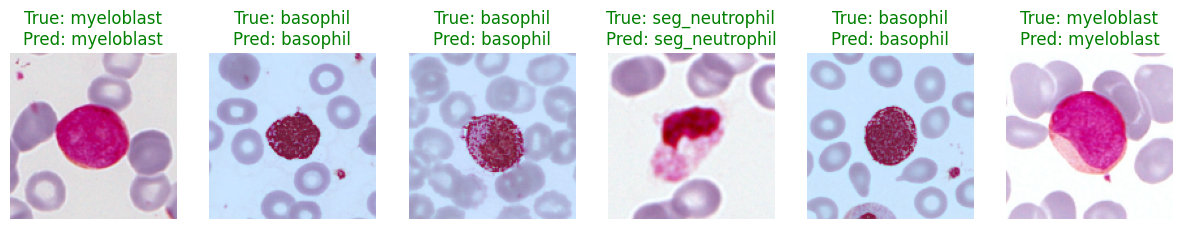

In [45]:
import matplotlib.pyplot as plt
import numpy as np

def visualize_predictions(model, X_test_raw, X_test_od, X_test_diffused, y_test, class_names, num_samples=5):
    """
    Displays images with their true and predicted labels.

    Args:
        model: Trained Keras model.
        X_test_raw: Raw test images.
        X_test_od: Optical density transformed test images.
        X_test_diffused: Diffused test images.
        y_test: True labels (one-hot encoded).
        class_names: List of class names.
        num_samples: Number of images to display.
    """
    # Convert y_test from one-hot encoding to integer labels
    y_test_int = np.argmax(y_test, axis=1)

    # Get predictions
    y_pred_probs = model.predict([X_test_raw, X_test_od, X_test_diffused])
    y_pred_classes = np.argmax(y_pred_probs, axis=1)

    # Select random samples to display
    indices = np.random.choice(len(X_test_raw), num_samples, replace=False)

    plt.figure(figsize=(15, 6))
    for i, idx in enumerate(indices):
        plt.subplot(1, num_samples, i + 1)
        plt.imshow(X_test_raw[idx])  # Show raw image
        true_label = class_names[y_test_int[idx]]
        pred_label = class_names[y_pred_classes[idx]]
        color = "green" if true_label == pred_label else "red"
        plt.title(f"True: {true_label}\nPred: {pred_label}", color=color)
        plt.axis("off")

    plt.show()

# Example usage:
visualize_predictions(model, X_test_raw, X_test_od, X_test_diffused, y_test, 
                      class_names=['basophil', 'erythroblast', 'monocyte', 'myeloblast', 'seg_neutrophil'], 
                      num_samples=6)


125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step


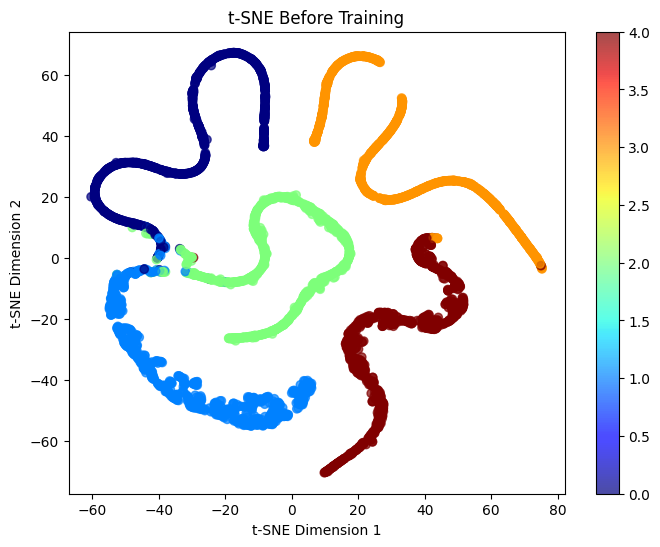

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step


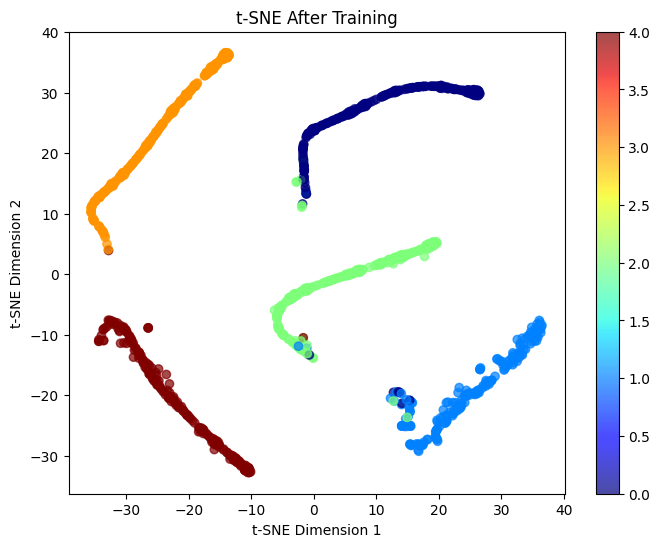

In [47]:
from sklearn.manifold import TSNE
import numpy as np
import matplotlib.pyplot as plt

def plot_tsne(features, labels, title):
    """
    Plots 2D t-SNE visualization of extracted features.

    Args:
        features: Extracted feature vectors (shape: [N, feature_dim]).
        labels: One-hot or integer encoded labels (shape: [N] or [N, num_classes]).
        title: Title of the plot.
    """
    # Convert one-hot labels to integer labels if needed
    if len(labels.shape) > 1 and labels.shape[1] > 1:
        labels = np.argmax(labels, axis=1)  # Convert from one-hot to single class index

    # Apply t-SNE transformation
    tsne = TSNE(n_components=2, perplexity=30, random_state=42)
    reduced_features = tsne.fit_transform(features)

    # Plot the t-SNE scatter plot
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(reduced_features[:, 0], reduced_features[:, 1], c=labels, cmap="jet", alpha=0.7)
    plt.colorbar(scatter)
    plt.title(title)
    plt.xlabel("t-SNE Dimension 1")
    plt.ylabel("t-SNE Dimension 2")
    plt.show()

# Example usage (Before Training)
raw_features = model.predict([X_train_raw, X_train_od, X_train_diffused])
plot_tsne(raw_features, y_train, title="t-SNE Before Training")

# Example usage (After Training)
trained_features = model.predict([X_test_raw, X_test_od, X_test_diffused])
plot_tsne(trained_features, y_test, title="t-SNE After Training")


125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step


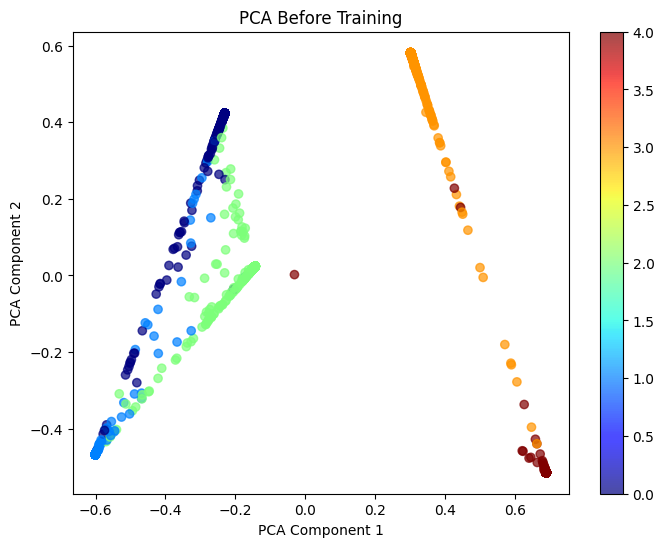

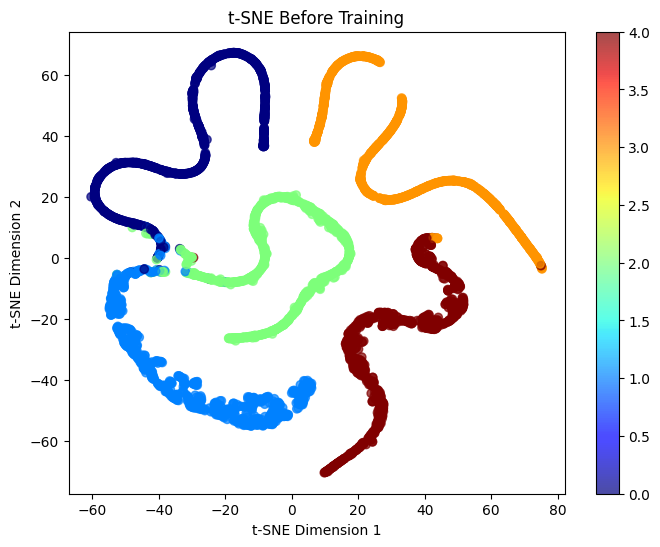

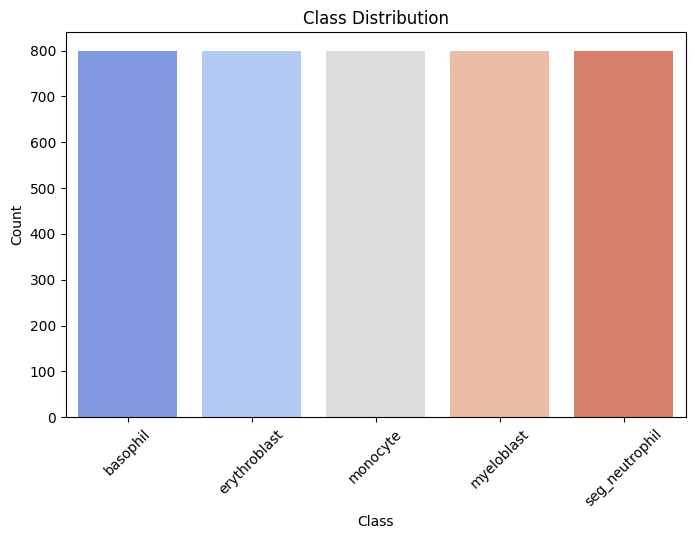

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


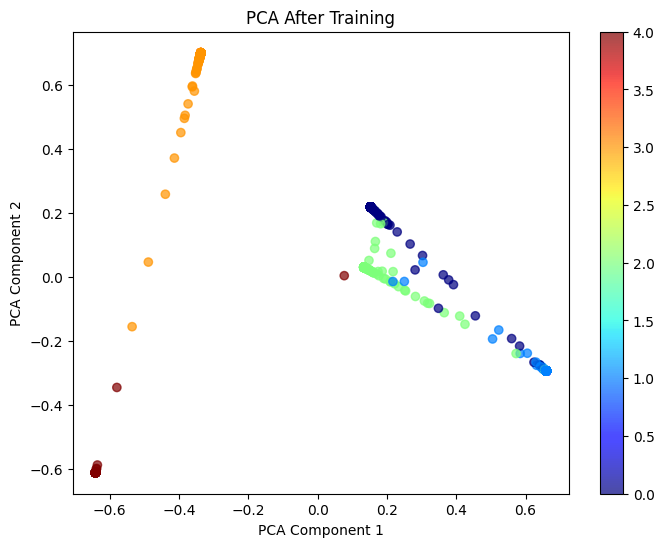

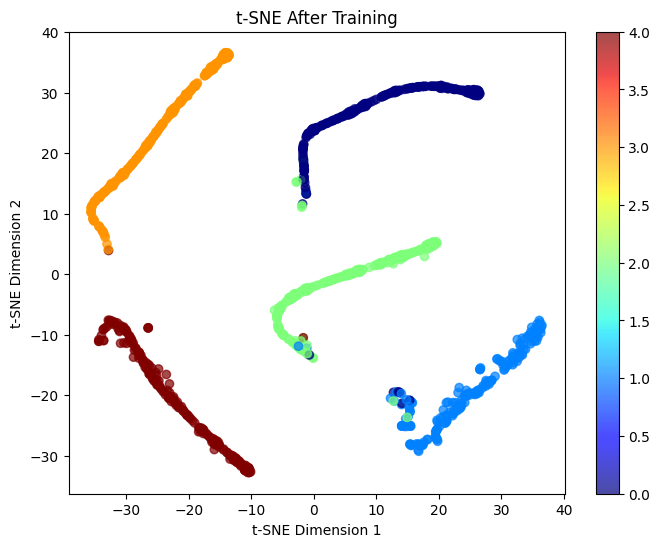

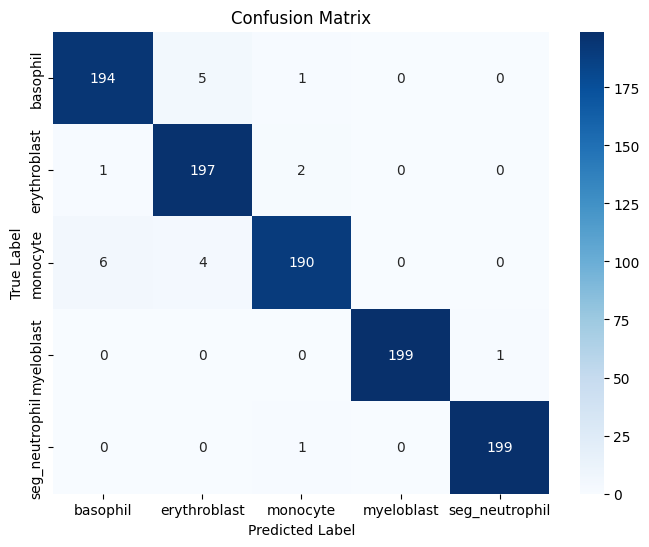

In [48]:
import seaborn as sns
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

def plot_pca(features, labels, title):
    """
    Plots 2D PCA visualization of extracted features.

    Args:
        features: Extracted feature vectors (shape: [N, feature_dim]).
        labels: One-hot or integer encoded labels (shape: [N] or [N, num_classes]).
        title: Title of the plot.
    """
    # Convert one-hot labels to integer labels if needed
    if len(labels.shape) > 1 and labels.shape[1] > 1:
        labels = np.argmax(labels, axis=1)

    # Apply PCA
    pca = PCA(n_components=2)
    reduced_features = pca.fit_transform(features)

    # Plot the PCA scatter plot
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(reduced_features[:, 0], reduced_features[:, 1], c=labels, cmap="jet", alpha=0.7)
    plt.colorbar(scatter)
    plt.title(title)
    plt.xlabel("PCA Component 1")
    plt.ylabel("PCA Component 2")
    plt.show()

def plot_tsne(features, labels, title):
    """
    Plots 2D t-SNE visualization of extracted features.

    Args:
        features: Extracted feature vectors (shape: [N, feature_dim]).
        labels: One-hot or integer encoded labels (shape: [N] or [N, num_classes]).
        title: Title of the plot.
    """
    if len(labels.shape) > 1 and labels.shape[1] > 1:
        labels = np.argmax(labels, axis=1)

    tsne = TSNE(n_components=2, perplexity=30, random_state=42)
    reduced_features = tsne.fit_transform(features)

    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(reduced_features[:, 0], reduced_features[:, 1], c=labels, cmap="jet", alpha=0.7)
    plt.colorbar(scatter)
    plt.title(title)
    plt.xlabel("t-SNE Dimension 1")
    plt.ylabel("t-SNE Dimension 2")
    plt.show()

def plot_confusion_matrix(y_true, y_pred, class_names):
    """
    Plots a confusion matrix.

    Args:
        y_true: Ground truth labels (integer encoded).
        y_pred: Predicted labels (integer encoded).
        class_names: List of class names.
    """
    if len(y_true.shape) > 1 and y_true.shape[1] > 1:
        y_true = np.argmax(y_true, axis=1)

    cm = confusion_matrix(y_true, y_pred)
    df_cm = pd.DataFrame(cm, index=class_names, columns=class_names)

    plt.figure(figsize=(8, 6))
    sns.heatmap(df_cm, annot=True, fmt="d", cmap="Blues")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title("Confusion Matrix")
    plt.show()

def plot_distribution(labels, class_names):
    """
    Plots class distribution in the dataset.

    Args:
        labels: Ground truth labels (integer encoded).
        class_names: List of class names.
    """
    if len(labels.shape) > 1 and labels.shape[1] > 1:
        labels = np.argmax(labels, axis=1)

    df = pd.DataFrame({"Class": labels})
    plt.figure(figsize=(8, 5))
    sns.countplot(x="Class", data=df, palette="coolwarm")
    plt.xticks(ticks=np.arange(len(class_names)), labels=class_names, rotation=45)
    plt.title("Class Distribution")
    plt.xlabel("Class")
    plt.ylabel("Count")
    plt.show()

# Example usage (Before Training)
raw_features = model.predict([X_train_raw, X_train_od, X_train_diffused])
plot_pca(raw_features, y_train, title="PCA Before Training")
plot_tsne(raw_features, y_train, title="t-SNE Before Training")
plot_distribution(y_train, class_names=['basophil', 'erythroblast', 'monocyte', 'myeloblast', 'seg_neutrophil'])

# Example usage (After Training)
trained_features = model.predict([X_test_raw, X_test_od, X_test_diffused])
y_pred_classes = np.argmax(trained_features, axis=1)

plot_pca(trained_features, y_test, title="PCA After Training")
plot_tsne(trained_features, y_test, title="t-SNE After Training")
plot_confusion_matrix(y_test, y_pred_classes, class_names=['basophil', 'erythroblast', 'monocyte', 'myeloblast', 'seg_neutrophil'])


  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━

  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━

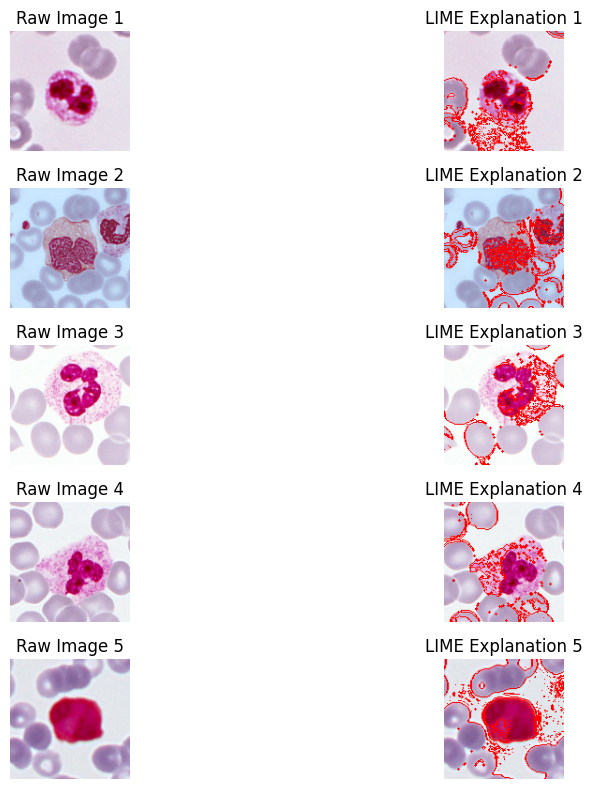

In [49]:
import matplotlib.pyplot as plt
import lime
import lime.lime_image
from skimage.segmentation import mark_boundaries
import numpy as np

def explain_with_lime(model, X_test_raw, num_samples=5, num_features=10):
    """
    Uses LIME to explain the model's decision for multiple test images.

    Args:
        model: Trained Keras model.
        X_test_raw: Raw test images.
        num_samples: Number of images to visualize.
        num_features: Number of superpixels to highlight.
    """
    explainer = lime.lime_image.LimeImageExplainer()

    plt.figure(figsize=(12, 8))
    
    # Select random samples to explain
    indices = np.random.choice(len(X_test_raw), num_samples, replace=False)

    for i, idx in enumerate(indices):
        X_sample = X_test_raw[idx]
        
        def predict_fn(images):
            return model.predict([images, images, images])  # Pass through all three inputs

        explanation = explainer.explain_instance(
            X_sample.astype('double'),
            predict_fn,
            top_labels=5,
            hide_color=0,
            num_samples=1000
        )

        temp, mask = explanation.get_image_and_mask(
            explanation.top_labels[0],
            positive_only=True,
            num_features=num_features,
            hide_rest=False
        )

        # Superimpose LIME explanation on raw image
        lime_overlay = mark_boundaries(X_sample, mask, color=(1, 0, 0))

        # Plot Raw Image and LIME Explanation Overlay
        plt.subplot(num_samples, 2, i * 2 + 1)
        plt.imshow(X_sample.astype("uint8"))
        plt.title(f"Raw Image {i+1}")
        plt.axis('off')

        plt.subplot(num_samples, 2, i * 2 + 2)
        plt.imshow(lime_overlay)
        plt.title(f"LIME Explanation {i+1}")
        plt.axis('off')

    plt.tight_layout()
    plt.show()

# Example usage:
explain_with_lime(model, X_test_raw, num_samples=5, num_features=10)


In [51]:
import seaborn as sns
import pandas as pd
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

def plot_normalized_confusion_matrix(y_true, y_pred, class_names):
    """
    Plots a normalized confusion matrix.

    Args:
        y_true: Ground truth labels (integer encoded).
        y_pred: Predicted labels (integer encoded).
        class_names: List of class names.
    """
    if len(y_true.shape) > 1 and y_true.shape[1] > 1:
        y_true = np.argmax(y_true, axis=1)

    cm = confusion_matrix(y_true, y_pred, normalize='true')  # Normalize by row (true labels)
    df_cm = pd.DataFrame(cm, index=class_names, columns=class_names)

    plt.figure(figsize=(8, 6))
    sns.heatmap(df_cm, annot=True, fmt=".2f", cmap="Blues", cbar=True)
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title("Normalized Confusion Matrix")
    plt.show()

def ablation_study(model, X_test_raw, X_test_od, X_test_diffused, y_test, class_names):
    """
    Performs an ablation study by evaluating the model with different input combinations.

    Args:
        model: Trained Keras model.
        X_test_raw: Raw test images.
        X_test_od: Optical Density transformed test images.
        X_test_diffused: Diffused test images.
        y_test: True labels (one-hot encoded or integer labels).
        class_names: List of class names.
    """
    if len(y_test.shape) > 1 and y_test.shape[1] > 1:
        y_test_int = np.argmax(y_test, axis=1)
    else:
        y_test_int = y_test

    # Evaluate full model (all three inputs)
    full_pred = np.argmax(model.predict([X_test_raw, X_test_od, X_test_diffused]), axis=1)
    full_acc = np.mean(full_pred == y_test_int)

    # Evaluate without OD images
    raw_diff_pred = np.argmax(model.predict([X_test_raw, np.zeros_like(X_test_od), X_test_diffused]), axis=1)
    raw_diff_acc = np.mean(raw_diff_pred == y_test_int)

    # Evaluate without Diffused images
    raw_od_pred = np.argmax(model.predict([X_test_raw, X_test_od, np.zeros_like(X_test_diffused)]), axis=1)
    raw_od_acc = np.mean(raw_od_pred == y_test_int)

    # Evaluate with only Raw images
    raw_pred = np.argmax(model.predict([X_test_raw, np.zeros_like(X_test_od), np.zeros_like(X_test_diffused)]), axis=1)
    raw_acc = np.mean(raw_pred == y_test_int)

    # Bar plot for ablation study
    accuracies = [full_acc, raw_diff_acc, raw_od_acc, raw_acc]
    conditions = ["Full Model", "Without OD", "Without Diffused", "Raw Only"]

    plt.figure(figsize=(8, 5))
    sns.barplot(x=conditions, y=accuracies, palette="coolwarm")
    plt.ylabel("Accuracy")
    plt.xlabel("Model Variation")
    plt.title("Ablation Study: Impact of Removing Inputs")
    plt.ylim(0, 1)  # Set y-axis from 0 to 1 (accuracy range)
    plt.show()

    # Print the accuracy values
    for cond, acc in zip(conditions, accuracies):
        print(f"{cond}: {acc:.4f}")






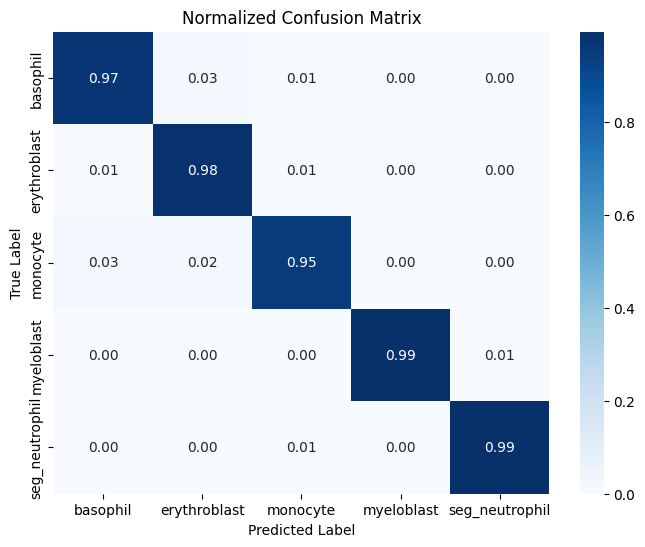

In [52]:
plot_normalized_confusion_matrix(y_test, y_pred_classes, class_names=['basophil', 'erythroblast', 'monocyte', 'myeloblast', 'seg_neutrophil'])

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1765: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  order = pd.unique(vector)


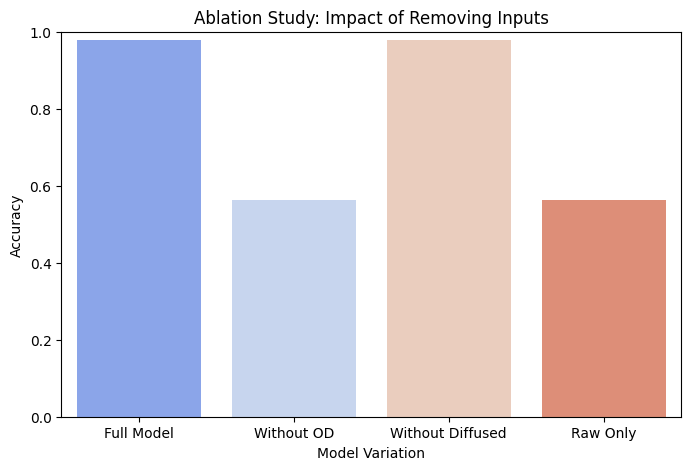

Full Model: 0.9790
Without OD: 0.5640
Without Diffused: 0.9790
Raw Only: 0.5630


In [54]:
ablation_study(model, X_test_raw, X_test_od, X_test_diffused, y_test, class_names=['basophil', 'erythroblast', 'monocyte', 'myeloblast', 'seg_neutrophil'])